# Getting started with transitmatters

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/transitmatters/transitmatters-py/blob/main/examples/getting-started.ipynb)

`transitmatters` fetches MBTA performance data from the
[TransitMatters Data Dashboard](https://dashboard.transitmatters.org): how long
trips took, how long riders waited, ridership, and more. This notebook uses it
to find out how long a Red Line ride from Davis to Park Street takes, and how
that has changed.

Run the cells in order with **Shift+Enter**. The data comes from TransitMatters'
public API, and no key is needed.

## Install

Skip this cell if you've already installed `transitmatters`.

In [ ]:
%pip install 'transitmatters[pandas]' matplotlib

## Connect to the API

Every request is a method on the `TransitMatters` client. `Line` names the
subway lines, and `to_dataframe` turns results into pandas DataFrames.

In [1]:
from transitmatters import Line, TransitMatters, to_dataframe

tm = TransitMatters()

## Find the stops

The API records each train at a platform, and each direction has its own
platform with its own stop ID. `stops` lists a line's stations and their
platforms, along with the line's direction names:

In [2]:
red = tm.stops(Line.RED)
red.directions

{0: 'northbound', 1: 'southbound'}

You don't need to look up platforms yourself. `trip` finds the direction of
travel between two stations and the platforms to use:

In [3]:
pair = red.trip("Davis", "Park Street")
pair

StopPair(from_stop=('70063',), to_stop=('70075',), direction=1)

## Get every trip in a month

`travel_times` returns one item for each trip between the two platforms. Dates
can be `"YYYY-MM-DD"` strings or `datetime.date` objects, and a range includes
both ends.

In [4]:
trips = tm.travel_times(
    "2025-03-01", "2025-03-31", from_stop=pair.from_stop, to_stop=pair.to_stop
)
len(trips)

5561

In [5]:
trips[0]

TravelTime(route_id='Red', direction=0, dep_dt=datetime.datetime(2025, 3, 1, 5, 18, 1, tzinfo=zoneinfo.ZoneInfo(key='America/New_York')), arr_dt=datetime.datetime(2025, 3, 1, 5, 31, 28, tzinfo=zoneinfo.ZoneInfo(key='America/New_York')), travel_time_sec=807.0, benchmark_travel_time_sec=900.0, tm_benchmark_travel_time_sec=900, vehicle_label='1920', vehicle_consist=())

## Analyze it with pandas

`to_dataframe` makes a DataFrame with one row per trip and one column per
field. Times are in Eastern time.

In [6]:
df = to_dataframe(trips)
df[["dep_dt", "arr_dt", "travel_time_sec"]].head()

,dep_dt,arr_dt,travel_time_sec
0,2025-03-01 05:18:01-05:00,2025-03-01 05:31:28-05:00,807.0
1,2025-03-01 05:28:53-05:00,2025-03-01 05:42:44-05:00,831.0
2,2025-03-01 05:37:37-05:00,2025-03-01 05:51:16-05:00,819.0
3,2025-03-01 05:46:33-05:00,2025-03-01 05:59:44-05:00,791.0
4,2025-03-01 05:53:33-05:00,2025-03-01 06:07:38-05:00,845.0


Grouping weekday trips by the hour they left Davis shows rush hour: trips at
8 AM and 4 PM take more than a minute longer than trips at 5 AM.

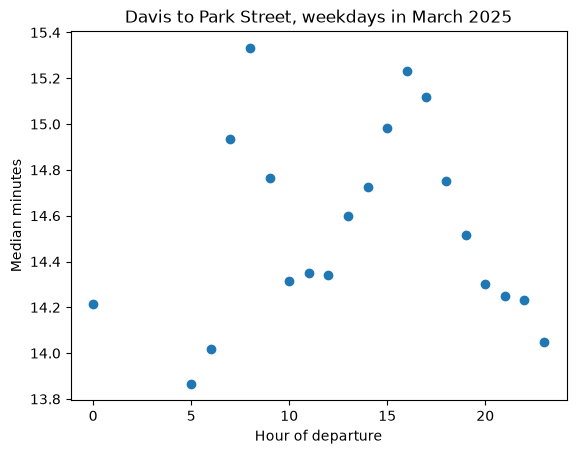

In [7]:
weekdays = df[df["dep_dt"].dt.dayofweek < 5]
minutes = weekdays["travel_time_sec"] / 60
by_hour = minutes.groupby(weekdays["dep_dt"].dt.hour).median()
by_hour.plot(
    style="o",
    xlabel="Hour of departure",
    ylabel="Median minutes",
    title="Davis to Park Street, weekdays in March 2025",
);

## Look at a longer trend

Methods named `aggregate_...` summarize each day instead of returning every
event, so they cover years in one request. Here's the median trip time each
day for three years, with a typical value for each month. The rise in 2023 is
the MBTA's slow zones, speed limits on track that needed repair; track work
through 2024 removed them.

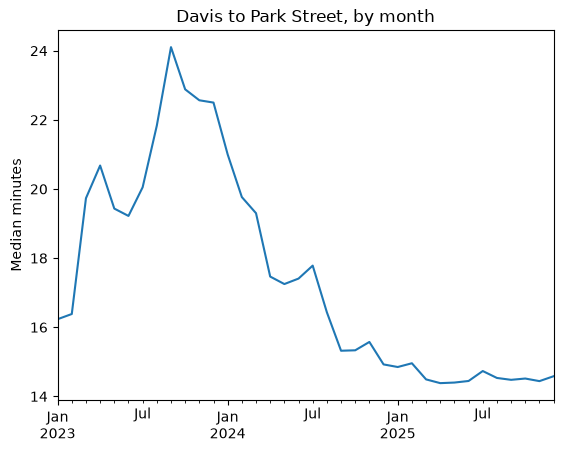

In [8]:
days = to_dataframe(
    tm.aggregate_travel_times(
        "2023-01-01", "2025-12-31", from_stop=pair.from_stop, to_stop=pair.to_stop
    )
)
monthly = days.set_index("service_date")["p50"].resample("MS").median() / 60
monthly.plot(
    ylabel="Median minutes", xlabel="", title="Davis to Park Street, by month"
);

## Next steps

- The [API docs](https://transitmatters.github.io/transitmatters-py/transitmatters.html) list every method. Start with
  [Which method do I want?](https://transitmatters.github.io/transitmatters-py/transitmatters.html#which-method-do-i-want)
- For buses, commuter rail, and ferries, pass a route ID string instead of a
  `Line`, such as `tm.stops("66")` or `tm.stops("CR-Fairmount")`.
  `tm.routes()` lists them all.
- Try `tm.headways` for the time between trains at a stop, or `tm.ridership`
  for weekly ridership on a line.